In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester
from src.strategies import run_momentum_strategy, generate_momentum_signal

In [2]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252

In [3]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)
momentum_signal = generate_momentum_signal(prices, lookback)
momentum_position = momentum_df["position"]

#### Structure - Exploratory Analysis

In [ ]:
def analyse_runs(run):

    short = 0
    medium = 0
    long = 0

    short_days = 0
    medium_days = 0
    long_days = 0
    
    for i in range(len(run)):
        if run[i] <= 10:
            short += 1
            short_days += int(run[i])
        elif 10 < run[i] <= 100:
            medium += 1
            medium_days += int(run[i])
        else:
            long += 1
            long_days += int(run[i])

    return {
    "short_runs": short,
    "medium_runs": medium,
    "long_runs": long,
    "short_days": short_days,
    "medium_days": medium_days,
    "long_days": long_days
}

In [4]:
run_boundaries = []

run_boundaries.append(lookback + 1)

for i in range(lookback + 2, len(momentum_position)):
    if momentum_position.iloc[i] != momentum_position.iloc[i - 1]:
        run_boundaries.append(i)

run_boundaries.append(len(momentum_position))

run_boundaries

[253,
 271,
 272,
 552,
 553,
 556,
 557,
 558,
 562,
 568,
 570,
 572,
 573,
 863,
 864,
 866,
 867,
 870,
 875,
 876,
 2020,
 2049,
 2050,
 2455,
 2957,
 2959,
 2994,
 2996,
 3009,
 3012,
 3114,
 3116,
 3122,
 3123,
 3124,
 3125,
 3935,
 3938,
 3941,
 3945,
 3946,
 3948,
 3953,
 3958,
 3959,
 3962,
 4017,
 4019,
 4026,
 4027,
 4029,
 4074,
 4075,
 4078,
 4079,
 4082,
 4092,
 4094,
 4109,
 4110,
 4113,
 4114,
 4117,
 4124,
 4141,
 4142,
 4146,
 4148,
 4769,
 4803,
 5080,
 5105,
 5106,
 5113,
 5115,
 5118,
 5623,
 5630,
 5631,
 5638,
 5639,
 5641,
 5642,
 5867,
 5869,
 5870,
 5872,
 5874,
 6353,
 6356,
 6713]

In [5]:
run_lengths = []

for i in range(1, len(run_boundaries)):
    difference = float(run_boundaries[i]) - float(run_boundaries[i - 1])

    run_lengths.append(difference)

run_lengths

[18.0,
 1.0,
 280.0,
 1.0,
 3.0,
 1.0,
 1.0,
 4.0,
 6.0,
 2.0,
 2.0,
 1.0,
 290.0,
 1.0,
 2.0,
 1.0,
 3.0,
 5.0,
 1.0,
 1144.0,
 29.0,
 1.0,
 405.0,
 502.0,
 2.0,
 35.0,
 2.0,
 13.0,
 3.0,
 102.0,
 2.0,
 6.0,
 1.0,
 1.0,
 1.0,
 810.0,
 3.0,
 3.0,
 4.0,
 1.0,
 2.0,
 5.0,
 5.0,
 1.0,
 3.0,
 55.0,
 2.0,
 7.0,
 1.0,
 2.0,
 45.0,
 1.0,
 3.0,
 1.0,
 3.0,
 10.0,
 2.0,
 15.0,
 1.0,
 3.0,
 1.0,
 3.0,
 7.0,
 17.0,
 1.0,
 4.0,
 2.0,
 621.0,
 34.0,
 277.0,
 25.0,
 1.0,
 7.0,
 2.0,
 3.0,
 505.0,
 7.0,
 1.0,
 7.0,
 1.0,
 2.0,
 1.0,
 225.0,
 2.0,
 1.0,
 2.0,
 2.0,
 479.0,
 3.0,
 357.0]

In [6]:
cash_runs = run_lengths[::2]
invested_runs = run_lengths[1::2]

In [ ]:
run_analysis = analyse_runs(run_lengths)
run_analysis

In [ ]:
cash_analysis = analyse_runs(cash_runs)
cash_analysis

In [ ]:
invested_analysis = analyse_runs(invested_runs)
invested_analysis

In [ ]:
long_cash_runs = []

for i in range(len(cash_runs)):
    if cash_runs[i] > 100:
        long_cash_runs.append(cash_runs[i])

long_cash_runs

In [ ]:
long_invested_runs = []

for i in range(len(invested_runs)):
    if invested_runs[i] > 100:
        long_invested_runs.append(invested_runs[i])

long_invested_runs

In [ ]:
print(np.mean(long_cash_runs), 
      np.median(long_cash_runs), 
      np.mean(long_invested_runs), 
      np.median(long_invested_runs)
      )

#### Run Length Permutation Random Strategy

In [7]:
random_cash_sequence = np.random.permutation(cash_runs).astype(int)
random_invested_sequence = np.random.permutation(invested_runs).astype(int)

In [ ]:
random_cash_sequence

In [ ]:
random_invested_sequence

In [8]:
sequence = []
    
for i in range(len(cash_runs)):
    
    sequence.extend([0] * random_cash_sequence[i])
    sequence.extend([1] * random_invested_sequence[i])

sequence.append(np.nan)

random_signal = ([np.nan] * lookback) + sequence

In [9]:
random_df, random_results = backtester(returns, random_signal, 0.001)
random_df

,return,signal,position,strategy_return,transaction_cost,net_strategy_return,equity,running_peak,drawdown
0,NaN,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN
1,-0.039107,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN
2,0.001789,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN
3,-0.016072,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN
4,0.058077,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
6708,-0.003854,0.0,0.0,-0.000000,0.000,-0.000000,3.785643,3.893879,-0.027796
6709,-0.005492,1.0,0.0,-0.000000,0.000,-0.000000,3.785643,3.893879,-0.027796
6710,-0.004648,1.0,1.0,-0.004648,0.001,-0.005648,3.764263,3.893879,-0.033287
6711,-0.005994,1.0,1.0,-0.005994,0.000,-0.005994,3.741699,3.893879,-0.039082


In [34]:
pd.Series(random_results)

total_return          2.053931
cagr                  0.044513
annual_volatility     0.174332
annual_sharpe         0.337001
max_drawdown         -0.551895
calmar                0.080656
time_invested         0.775232
trades               89.000000
dtype: float64

In [21]:
def generate_random_signal_v5(prices, lookback):

    momentum_df, _ = run_momentum_strategy(prices, returns, lookback, 0.001)
    momentum_position = momentum_df["position"]

    run_boundaries = []
    
    run_boundaries.append(lookback + 1)
    
    for i in range(lookback + 2, len(momentum_position)):
        if momentum_position.iloc[i] != momentum_position.iloc[i - 1]:
            run_boundaries.append(i)
    
    run_boundaries.append(len(momentum_position))

    run_lengths = []
    
    for i in range(1, len(run_boundaries)):
        difference = float(run_boundaries[i]) - float(run_boundaries[i - 1])
    
        run_lengths.append(difference)

    cash_runs = run_lengths[::2]
    invested_runs = run_lengths[1::2]

    random_cash_sequence = np.random.permutation(cash_runs).astype(int)
    random_invested_sequence = np.random.permutation(invested_runs).astype(int)

    sequence = []
        
    for i in range(len(cash_runs)):
        
        sequence.extend([0] * random_cash_sequence[i])
        sequence.extend([1] * random_invested_sequence[i])
    
    sequence.append(np.nan)
    
    random_signal = ([np.nan] * lookback) + sequence

    return random_signal


In [17]:
def run_simulation_v5(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v5(prices, 252)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result

In [42]:
np.random.seed(44)

simulation_output = run_simulation_v5(1000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,10.880236,0.101357,0.137969,0.768838,-0.313847,0.322950,0.775232,89
1,5.539611,0.076005,0.161014,0.535479,-0.367422,0.206859,0.775232,89
2,4.644221,0.069842,0.174890,0.473505,-0.536205,0.130252,0.775232,89
3,3.623271,0.061547,0.163593,0.446895,-0.551895,0.111519,0.775232,89
4,3.431431,0.059793,0.172358,0.423175,-0.551895,0.108342,0.775232,89
...,...,...,...,...,...,...,...,...
995,5.074617,0.072913,0.173595,0.492323,-0.571790,0.127517,0.775232,89
996,3.616051,0.061482,0.153879,0.464847,-0.394606,0.155807,0.775232,89
997,4.298148,0.067204,0.150994,0.506506,-0.420287,0.159901,0.775232,89
998,3.220776,0.057782,0.169755,0.415882,-0.608537,0.094952,0.775232,89


In [44]:
print(f"Sharpe Average: {simulation_df['annual_sharpe'].mean():.4f}")
print(f"Sharpe Median:  {simulation_df['annual_sharpe'].median():.4f}")
print(f"Largest Sharpe: {simulation_df['annual_sharpe'].max():.4f}")
print(f"Average No. of Trades: {simulation_df['trades'].mean():.4f}")
print(f"Average Time Invested: {simulation_df['time_invested'].mean():.4f}")

Sharpe Average: 0.4695
Sharpe Median:  0.4553
Largest Sharpe: 0.8610
Average No. of Trades: 89.0000
Average Time Invested: 0.7752


In [45]:
fraction_numerator = 0

simulation_sharpe_ratio = simulation_df["annual_sharpe"]

for i in range(len(simulation_sharpe_ratio)):
    if simulation_sharpe_ratio[i] >= momentum_results["annual_sharpe"]:
        fraction_numerator += 1

p_value = fraction_numerator/len(simulation_sharpe_ratio)

print("Empirical p-value:", p_value)

Empirical p-value: 0.072


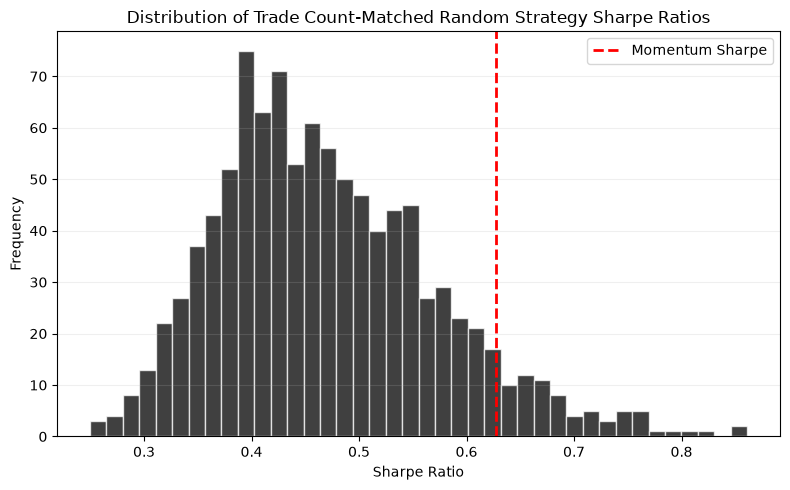

In [46]:
plt.figure(figsize=(8, 5))

plt.hist(
    simulation_df["annual_sharpe"],
    bins=40,
    color="black",
    alpha=0.75,
    edgecolor="white"
)

plt.axvline(
    momentum_results["annual_sharpe"],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Momentum Sharpe"
)

plt.xlabel("Sharpe Ratio")
plt.ylabel("Frequency")
plt.title("Distribution of Trade Count-Matched Random Strategy Sharpe Ratios")

plt.legend()

plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

In [10]:
%timeit backtester(returns, random_signal, 0.001)

3.61 ms ± 201 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [11]:
%%timeit

random_cash_sequence = np.random.permutation(cash_runs).astype(int)
random_invested_sequence = np.random.permutation(invested_runs).astype(int)

8.68 μs ± 23.3 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


In [14]:
%%timeit

sequence = []
        
for i in range(len(cash_runs)):
        
    sequence.extend([0] * random_cash_sequence[i])
    sequence.extend([1] * random_invested_sequence[i])
    
    sequence.append(np.nan)
    
random_signal = ([np.nan] * lookback) + sequence

49.7 μs ± 121 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [ ]:
%%timeit

run_boundaries = []
    
run_boundaries.append(lookback + 1)
    
for i in range(lookback + 2, len(momentum_position)):
    if momentum_position.iloc[i] != momentum_position.iloc[i - 1]:
        run_boundaries.append(i)
    
run_boundaries.append(len(momentum_position))

run_lengths = []
    
for i in range(1, len(run_boundaries)):
    difference = float(run_boundaries[i]) - float(run_boundaries[i - 1])
    
    run_lengths.append(difference)

cash_runs = run_lengths[::2]
invested_runs = run_lengths[1::2]

28.5 ms ± 320 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [19]:
%timeit run_simulation_v5(1)

66.1 ms ± 899 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [22]:
%timeit generate_random_signal_v5

7.78 ns ± 0.0215 ns per loop (mean ± std. dev. of 7 runs, 100,000,000 loops each)
